In [1]:
import sys
from pathlib import Path
import numpy as np
import scipy.special
import scipy.stats
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

# Ensure repository root is importable when running from EXERCISES/ or exercise_solutions/
REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / "sbi_lecture").exists():
    REPO_ROOT = REPO_ROOT.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

try:
    plt.style.use("bayesian_stats_course_tools.light")
except Exception:
    plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["text.usetex"] = False

from sbi_lecture import interactive_widgets as iw

# Mystery Galton Board experimental configuration
N_ROWS = 12
N_BALLS = 100
ALPHA_MIN, ALPHA_MAX = -1.5, 1.5
KAPPA_MIN, KAPPA_MAX = 0.0, 3.0
PRIOR_AREA = (ALPHA_MAX - ALPHA_MIN) * (KAPPA_MAX - KAPPA_MIN)

# Observed 100-ball histogram from the Mystery Galton Machine (bins k = 0, ..., 12)
x_obs = np.array([0, 0, 0, 0, 0, 7, 39, 38, 14, 2, 0, 0, 0], dtype=int)

# A second mystery board for testing amortized inference without retraining
x_obs_B = np.array([0, 0, 1, 9, 27, 38, 21, 4, 0, 0, 0, 0, 0], dtype=int)

print(f"Loaded Mystery Machine x_obs (sum={x_obs.sum()}): {x_obs.tolist()}")

Loaded Mystery Machine x_obs (sum=100): [0, 0, 0, 0, 0, 7, 39, 38, 14, 2, 0, 0, 0]


# Week 10 Exercises — Simulation-Based Inference on the Mystery Galton Board

**Course:** Bayesian Statistics and Data Analysis, ETH Zürich (HS2026)

---

## Problem Statement: The Mystery Galton Machine

A **generalized Galton board (Plinko machine)** has $R = 12$ rows of pegs. Each dropped ball starts at the top ($t = 0$, rightward count $k_0 = 0$) and bounces left or right through rows $t = 0, 1, \dots, R - 1$. After $t$ rows, its horizontal displacement from the center is:

$$s_t = 2 k_t - t, \qquad k_t \in \{0, 1, \dots, t\}.$$

Two unknown machine parameters $\theta = (\alpha, \kappa)$ govern the probability of bouncing **right** at row $t$:

$$P(\mathrm{right} \mid s_t, \alpha, \kappa) = \sigma\!\left(\alpha - \kappa \frac{s_t}{\sqrt{R}}\right), \qquad \sigma(z) = \frac{1}{1 + e^{-z}},$$

where:
- $\alpha \in [-1.5, 1.5]$ is the **horizontal tilt / bias**, and
- $\kappa \in [0, 3.0]$ is the **restoring pull toward the center** ($s_t = 0$).

We place a uniform prior $p(\alpha, \kappa) = \mathcal{U}(\alpha; -1.5, 1.5)\,\mathcal{U}(\kappa; 0, 3.0) = \frac{1}{9}$ on the prior box.
An experiment drops $N = 100$ independent balls and records only the final landing-bin histogram $x = (n_0, n_1, \dots, n_{12})$ with $\sum_{k=0}^{12} n_k = 100$—**intermediate peg trajectories are unobserved**.

When $\kappa > 0$, each ball's transition probability depends on its latent path $z = (s_0, \dots, s_{12})$, so $p(x \mid \theta) = \sum_z p(x, z \mid \theta)$ sums over $(2^{12})^{100}$ joint trajectories. In Exercises 1–4, treat the machine strictly as a **forward simulator** and infer $p(\alpha, \kappa \mid x_{\mathrm{obs}})$ using **Rejection ABC, NPE, NLE, and NRE**—then validate all four against an exact dynamic-programming recursion in Exercise 5.

Use the interactive simulator below to explore how $\alpha$ and $\kappa$ shape the landing histogram before writing code:

In [2]:
iw.demo("w02_plinko_sim")

<InteractiveDemo w02_plinko_sim: W02: Animated Mystery Galton Board Simulator>

---
## Warm-Up: Vectorized Forward Simulator

1. Implement `sample_prior(n_samples, rng)` returning an array of shape `(n_samples, 2)` with columns $(\alpha, \kappa) \sim \mathcal{U}(-1.5, 1.5) \times \mathcal{U}(0, 3.0)$.
2. Implement a vectorized forward simulator `simulate_galton_board(alphas, kappas, n_balls=100, n_rows=12, rng=None)` returning integer bin-count histograms of shape `(len(alphas), n_rows + 1)`.
3. **Sanity check:** Verify that when $\kappa = 0$, empirical bin frequencies from $50{,}000$ balls agree with the analytic $\mathrm{Binomial}(R, \sigma(\alpha))$ distribution.


### Warm-Up Solution

In [2]:
def sample_prior(n_samples: int, rng: np.random.Generator) -> np.ndarray:
    alphas = rng.uniform(ALPHA_MIN, ALPHA_MAX, size=n_samples)
    kappas = rng.uniform(KAPPA_MIN, KAPPA_MAX, size=n_samples)
    return np.column_stack([alphas, kappas])


def simulate_galton_board(
    alphas: np.ndarray | float,
    kappas: np.ndarray | float,
    n_balls: int = N_BALLS,
    n_rows: int = N_ROWS,
    rng: np.random.Generator | None = None,
) -> np.ndarray:
    if rng is None:
        rng = np.random.default_rng(42)
    a = np.atleast_1d(np.asarray(alphas, dtype=float))
    k = np.atleast_1d(np.asarray(kappas, dtype=float))
    m = a.shape[0]

    k_t = np.zeros((m, n_balls), dtype=int)
    sqrt_r = np.sqrt(float(n_rows))
    for t in range(n_rows):
        s_t = 2.0 * k_t - float(t)
        p_right = scipy.special.expit(a[:, None] - k[:, None] * (s_t / sqrt_r))
        k_t += (rng.random((m, n_balls)) < p_right).astype(int)

    hists = np.zeros((m, n_rows + 1), dtype=int)
    for b in range(n_rows + 1):
        hists[:, b] = np.sum(k_t == b, axis=1)
    return hists


# Sanity check: kappa = 0 recovers Binomial(R, sigmoid(alpha))
rng_check = np.random.default_rng(2026)
emp_hist = simulate_galton_board([0.5], [0.0], n_balls=50_000, rng=rng_check)[0] / 50_000.0
binom_pmf = scipy.stats.binom.pmf(np.arange(N_ROWS + 1), n=N_ROWS, p=scipy.special.expit(0.5))
print(f"Max |empirical - Binomial(12, sigma(0.5))| = {np.max(np.abs(emp_hist - binom_pmf)):.4f}")
assert np.max(np.abs(emp_hist - binom_pmf)) < 0.01

Max |empirical - Binomial(12, sigma(0.5))| = 0.0048


---
## Exercise 1: Rejection ABC & Summary Sufficiency

1. Generate a prior-predictive simulation bank $\mathcal{D}_{\mathrm{ABC}} = \{(\theta_i, x_i)\}_{i=1}^{M}$ with $M = 30{,}000$ draws.
2. Implement three discrepancy distances $d(x_i, x_{\mathrm{obs}})$:
   - **Mean-only summary:** $|\bar{k}(x_i) - \bar{k}(x_{\mathrm{obs}})|$, where $\bar{k}(x) = \frac{1}{N}\sum_{k=0}^{12} k\,n_k$.
   - **2D moment summary $(\bar{k}, s_k^2)$:** standardized Euclidean distance using sample mean $\bar{k}$ and variance $s_k^2$ normalized by their prior-predictive standard deviations.
   - **Full-histogram 1D Wasserstein ($W_1$) distance:** $W_1(x_i, x_{\mathrm{obs}}) = \sum_{k=0}^{11} |\hat{F}_i(k) - \hat{F}_{\mathrm{obs}}(k)|$, where $\hat{F}(k) = \frac{1}{N}\sum_{j \le k} n_j$ is the empirical CDF.
3. Run Rejection ABC across tolerances $\varepsilon$ and plot the accepted $(\alpha, \kappa)$ clouds for all three summaries.
   - Why does the mean-only summary fail to identify $\kappa$ even as $\varepsilon \to 0$?
   - What happens to Monte Carlo variance vs tolerance bias as $\varepsilon$ shrinks?


### Exercise 1 Solution: Rejection ABC & Summary Sufficiency

When we summarize a 100-ball histogram solely by its sample mean $\bar{k}$, distinct $(\alpha, \kappa)$ pairs produce the **same mean landing bin**: increasing restoring pull $\kappa$ pulls balls back toward the center ($k=6$), which can be compensated by increasing the tilt $\alpha$. Thus $\bar{k}$ alone is **insufficient** for $(\alpha, \kappa)$ and leaves an unidentifiable ridge even as $\varepsilon \to 0$. Including the sample variance $s_k^2$ (or the full 1D Wasserstein distance $W_1$) breaks the degeneracy because larger $\kappa$ narrows the spread.

/var/folders/fw/r_m3sngn55j51bkhkylg7yc40000gn/T/ipykernel_54367/1101666305.py:46: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  plt.tight_layout()
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


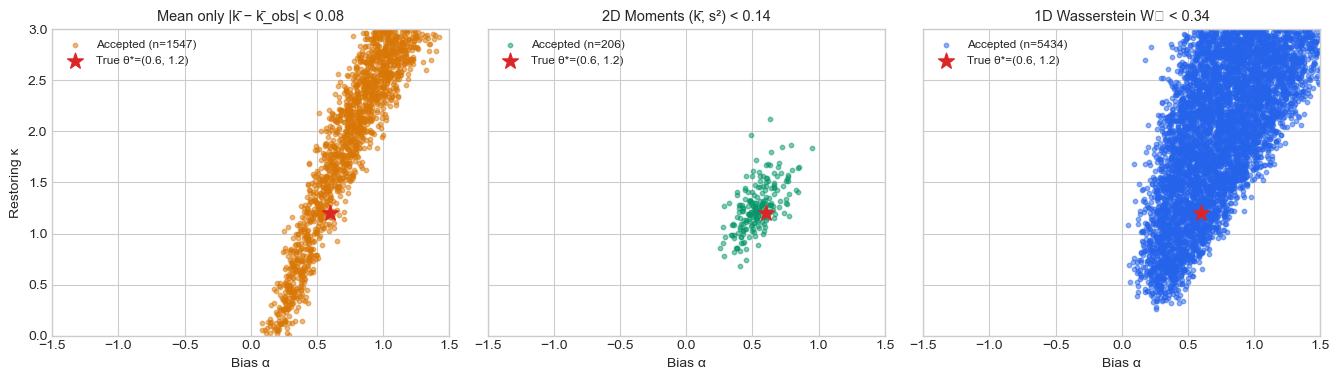

In [3]:
rng_abc = np.random.default_rng(101)
M_ABC = 30_000
thetas_abc = sample_prior(M_ABC, rng_abc)
hists_abc = simulate_galton_board(thetas_abc[:, 0], thetas_abc[:, 1], rng=rng_abc)

ks = np.arange(N_ROWS + 1, dtype=float)


def hist_moments(h: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    f = h / np.sum(h, axis=-1, keepdims=True)
    mean = np.sum(f * ks, axis=-1)
    var = np.sum(f * (ks - mean[..., None]) ** 2, axis=-1)
    return mean, var


m_sim, v_sim = hist_moments(hists_abc)
m_obs, v_obs = hist_moments(x_obs[None, :])

# 1. Mean-only distance
d_mean = np.abs(m_sim - m_obs[0])

# 2. Standardized 2D moment distance (mean, var)
sd_m, sd_v = np.std(m_sim), np.std(v_sim)
d_mom2 = np.sqrt(((m_sim - m_obs[0]) / sd_m) ** 2 + ((v_sim - v_obs[0]) / sd_v) ** 2)

# 3. Full-histogram 1D Wasserstein (CDF L1) distance
cdf_sim = np.cumsum(hists_abc / N_BALLS, axis=1)
cdf_obs = np.cumsum(x_obs / N_BALLS)[None, :]
d_wass = np.sum(np.abs(cdf_sim[:, :-1] - cdf_obs[:, :-1]), axis=1)

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.9), sharey=True)
configs = [
    ("Mean only |k̄ − k̄_obs| < 0.08", thetas_abc[d_mean < 0.08], "#d97706"),
    ("2D Moments (k̄, s²) < 0.14", thetas_abc[d_mom2 < 0.14], "#059669"),
    ("1D Wasserstein W₁ < 0.34", thetas_abc[d_wass < 0.34], "#2563eb"),
]
for ax, (title, acc, col) in zip(axes, configs):
    ax.scatter(acc[:, 0], acc[:, 1], s=10, alpha=0.5, color=col, label=f"Accepted (n={len(acc)})")
    ax.scatter([0.60], [1.20], marker="*", s=140, color="#dc2626", zorder=5, label="True θ*=(0.6, 1.2)")
    ax.set_xlim(ALPHA_MIN, ALPHA_MAX)
    ax.set_ylim(KAPPA_MIN, KAPPA_MAX)
    ax.set_xlabel("Bias α")
    ax.set_title(title, fontsize=10.5)
    ax.legend(loc="upper left", fontsize=8.5)
axes[0].set_ylabel("Restoring κ")
plt.tight_layout()
plt.show()

In [5]:
iw.demo("w06_plinko_abc")

<InteractiveDemo w06_plinko_abc: W06: Rejection ABC on the Mystery Galton Board>

---
## Exercise 2: Neural Posterior Estimation (NPE)

Instead of discarding $99\%$ of simulations with a hard ABC cutoff, **NPE** trains a conditional density $q_\phi(\theta \mid x)$ on *all* simulated pairs $(\theta_i, x_i) \sim p(\theta, x)$ by minimizing forward KL divergence—equivalently the empirical negative log-likelihood:

$$\mathcal{L}_{\mathrm{NPE}}(\phi) = -\frac{1}{M}\sum_{i=1}^M \log q_\phi(\theta_i \mid x_i).$$

To guarantee that $q_\phi(\alpha, \kappa \mid x)$ strictly respects the bounded prior box $[-1.5, 1.5] \times [0, 3.0]$, map physical parameters $\theta \in (a, b)$ to unconstrained coordinates $u \in \mathbb{R}^2$ via the **logit bijection**:

$$z = \frac{\theta - a}{b - a} \in (0, 1), \qquad u = \log\frac{z}{1 - z}, \qquad \log q_\phi(\theta \mid x) = \log q_\phi^{(u)}(u \mid x) - \sum_{d=1}^2 \log\bigl[(b_d - a_d)\,z_d(1 - z_d)\bigr].$$

1. Build a PyTorch conditional Mixture Density Network `GaltonNPE` ($K = 6$ or $8$ 2D Gaussian components in $u$-space conditioned on normalized histogram features) with exact `log_prob(theta, x)` and direct ancestral `sample(x_obs, n_samples)`.
2. Train `GaltonNPE` with AdamW on $M = 20{,}000$ training pairs while monitoring held-out validation NLL on $2{,}000$ independent pairs. Repeat with $M = 800$ pairs—what happens to the validation NLL curve?
3. Evaluate `GaltonNPE` on a $2\mathrm{D}$ grid for **both** `x_obs` and `x_obs_B` *without retraining*, demonstrating **amortized inference**.


### Exercise 2 Solution: Neural Posterior Estimation (NPE)

In [4]:
# Shared training (20,000) and held-out validation (2,500) simulation datasets for NPE, NLE, NRE
rng_nn = np.random.default_rng(202602)
th_train_np = sample_prior(20_000, rng_nn).astype(np.float32)
x_train_np = simulate_galton_board(th_train_np[:, 0], th_train_np[:, 1], rng=rng_nn).astype(np.float32)
th_val_np = sample_prior(2_500, rng_nn).astype(np.float32)
x_val_np = simulate_galton_board(th_val_np[:, 0], th_val_np[:, 1], rng=rng_nn).astype(np.float32)

th_train = torch.from_numpy(th_train_np)
x_train = torch.from_numpy(x_train_np)
th_val = torch.from_numpy(th_val_np)
x_val = torch.from_numpy(x_val_np)


def hist_features(x: torch.Tensor) -> torch.Tensor:
    freqs = x / torch.clamp(x.sum(dim=-1, keepdim=True), min=1.0)
    grid = torch.linspace(0.0, 1.0, x.shape[-1], device=x.device, dtype=x.dtype)
    m = (freqs * grid).sum(dim=-1, keepdim=True)
    v = (freqs * (grid - m) ** 2).sum(dim=-1, keepdim=True) * 10.0
    return torch.cat([freqs, (m - 0.5) * 2.0, v], dim=-1)


class GaltonNPE(nn.Module):
    """Logit-transformed 2D Cholesky Mixture Density Network q_phi(alpha, kappa | x)."""

    def __init__(self, n_components: int = 8, hidden_dim: int = 112):
        super().__init__()
        self.K = n_components
        self.enc = nn.Sequential(
            nn.Linear(N_ROWS + 3, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
        )
        self.logits = nn.Linear(hidden_dim, n_components)
        self.means = nn.Linear(hidden_dim, n_components * 2)
        self.chol = nn.Linear(hidden_dim, n_components * 3)

    def _params(self, x: torch.Tensor):
        h = self.enc(hist_features(x))
        log_w = F.log_softmax(self.logits(h), dim=-1)
        mu = self.means(h).view(-1, self.K, 2)
        c = self.chol(h).view(-1, self.K, 3)
        l11 = F.softplus(c[..., 0]) + 0.03
        l21 = c[..., 1]
        l22 = F.softplus(c[..., 2]) + 0.03
        return log_w, mu, l11, l21, l22

    def log_prob(self, theta: torch.Tensor, x: torch.Tensor) -> torch.Tensor:
        if x.shape[0] == 1 and theta.shape[0] > 1:
            x = x.expand(theta.shape[0], -1)
        lows = theta.new_tensor([ALPHA_MIN, KAPPA_MIN])
        spans = theta.new_tensor([ALPHA_MAX - ALPHA_MIN, KAPPA_MAX - KAPPA_MIN])
        z = torch.clamp((theta - lows) / spans, 1e-6, 1.0 - 1e-6)
        u = torch.log(z) - torch.log1p(-z)
        log_jac = torch.sum(torch.log(spans) + torch.log(z) + torch.log1p(-z), dim=-1)

        log_w, mu, l11, l21, l22 = self._params(x)
        du = u[:, None, :] - mu
        y1 = du[..., 0] / l11
        y2 = (du[..., 1] - l21 * y1) / l22
        log_g = -0.5 * (y1 ** 2 + y2 ** 2) - torch.log(l11) - torch.log(l22) - float(np.log(2.0 * np.pi))
        return torch.logsumexp(log_w + log_g, dim=-1) - log_jac

    @torch.no_grad()
    def sample(self, x_single: np.ndarray, n_samples: int = 2000, seed: int = 0) -> np.ndarray:
        rng = np.random.default_rng(seed)
        xt = torch.tensor(x_single, dtype=torch.float32).reshape(1, -1)
        log_w, mu, l11, l21, l22 = self._params(xt)
        w = torch.exp(log_w[0]).numpy()
        idx = rng.choice(self.K, size=n_samples, p=w / w.sum())
        eps = rng.standard_normal((n_samples, 2)).astype(np.float32)
        u1 = mu[0, idx, 0].numpy() + l11[0, idx].numpy() * eps[:, 0]
        u2 = mu[0, idx, 1].numpy() + l21[0, idx].numpy() * eps[:, 0] + l22[0, idx].numpy() * eps[:, 1]
        z = scipy.special.expit(np.column_stack([u1, u2]))
        return np.array([ALPHA_MIN, KAPPA_MIN]) + np.array([ALPHA_MAX - ALPHA_MIN, KAPPA_MAX - KAPPA_MIN]) * z


torch.manual_seed(10)
npe_model = GaltonNPE()
opt = torch.optim.AdamW(npe_model.parameters(), lr=2e-3, weight_decay=3e-5)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=45)

for ep in range(45):
    perm = torch.randperm(th_train.shape[0])
    for s in range(0, th_train.shape[0], 256):
        b = perm[s : s + 256]
        loss = -npe_model.log_prob(th_train[b], x_train[b]).mean()
        opt.zero_grad()
        loss.backward()
        opt.step()
    sched.step()

npe_model.eval()
with torch.no_grad():
    val_nll = float(-npe_model.log_prob(th_val, x_val).mean().item())
samples_A = npe_model.sample(x_obs, 3000, seed=1)
samples_B = npe_model.sample(x_obs_B, 3000, seed=2)
print(f"GaltonNPE Val NLL = {val_nll:.3f}")
print(f"Amortized x_obs   posterior mean: alpha = {samples_A[:,0].mean():.3f} ± {samples_A[:,0].std():.3f}, kappa = {samples_A[:,1].mean():.3f} ± {samples_A[:,1].std():.3f}")
print(f"Amortized x_obs_B posterior mean: alpha = {samples_B[:,0].mean():.3f} ± {samples_B[:,1].std():.3f}, kappa = {samples_B[:,1].mean():.3f} ± {samples_B[:,1].std():.3f}")

GaltonNPE Val NLL = -1.412
Amortized x_obs   posterior mean: alpha = 0.531 ± 0.094, kappa = 1.278 ± 0.210
Amortized x_obs_B posterior mean: alpha = -0.759 ± 0.158, kappa = 0.848 ± 0.158


In [7]:
iw.demo("wt_npe_plinko")

<InteractiveDemo wt_npe_plinko: Train NPE on the Galton Board: Conditional Posterior q_φ(α, κ | x_obs)>

---
## Exercise 3: Neural Likelihood Estimation (NLE) & Prior Swapping

**NLE** reverses the conditioning direction and learns a surrogate likelihood $q_\psi(x \mid \theta)$ by minimizing:

$$\mathcal{L}_{\mathrm{NLE}}(\psi) = -\frac{1}{M}\sum_{i=1}^M \log q_\psi(x_i \mid \theta_i).$$

Because $N = 100$ balls are dropped independently, $x \mid \theta$ follows a Multinomial distribution with unknown bin probabilities $\pi(\theta) \in \Delta^{12}$:

$$\log q_\psi(x \mid \theta) = \log\frac{N!}{\prod_{k=0}^{12} n_k!} + \sum_{k=0}^{12} n_k \log \hat{\pi}_{\psi, k}(\theta), \qquad \hat{\pi}_\psi(\theta) = \operatorname{softmax}\bigl(f_\psi(\theta)\bigr).$$

1. Implement `GaltonNLE` in PyTorch mapping normalized $(\alpha, \kappa) \in [-1, 1]^2$ through a `SiLU` MLP to `log_softmax` 13-bin log-probabilities, and train it on the same dataset $\mathcal{D}_{\mathrm{train}}$.
2. Compute the normalized posterior $p(\alpha, \kappa \mid x_{\mathrm{obs}}) \propto q_\psi(x_{\mathrm{obs}} \mid \alpha, \kappa)\,p(\alpha, \kappa)$ on a 2D grid (or sample it with 2,000 steps of Metropolis–Hastings).
3. **Live Prior Swapping:** Suppose a benchtop calibration reveals an informative prior $\alpha \sim \mathcal{N}(0.10, 0.25^2)$ (truncated to $[-1.5, 1.5]$). Compute and plot the updated posterior under `GaltonNLE` **without running any new simulations or gradient steps**. Why would a standard NPE network have to be retrained?


### Exercise 3 Solution: Neural Likelihood Estimation (NLE) & Prior Swapping

Because `GaltonNLE` approximates the **likelihood** $q_\psi(x \mid \theta)$ rather than a prior-specific posterior, changing $p(\theta) \to p'(\theta)$ only multiplies the already-learned likelihood surface by $p'(\theta)$—requiring **zero new simulations and zero retraining**.

In [5]:
class GaltonNLE(nn.Module):
    """Structured Multinomial surrogate likelihood predicting 13-bin log-probabilities."""

    def __init__(self, hidden_dim: int = 112):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, N_ROWS + 1),
        )

    def log_bin_probs(self, theta: torch.Tensor) -> torch.Tensor:
        t_norm = torch.stack([theta[:, 0] / 1.5, (theta[:, 1] - 1.5) / 1.5], dim=-1)
        return F.log_softmax(self.net(t_norm), dim=-1)

    def log_likelihood(self, x: torch.Tensor, theta: torch.Tensor) -> torch.Tensor:
        if x.shape[0] == 1 and theta.shape[0] > 1:
            x = x.expand(theta.shape[0], -1)
        log_p = self.log_bin_probs(theta)
        n_tot = x.sum(dim=-1)
        log_comb = torch.lgamma(n_tot + 1.0) - torch.lgamma(x + 1.0).sum(dim=-1)
        return log_comb + (x * log_p).sum(dim=-1)


torch.manual_seed(20)
nle_model = GaltonNLE()
opt = torch.optim.AdamW(nle_model.parameters(), lr=2e-3, weight_decay=3e-5)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=45)

for ep in range(45):
    perm = torch.randperm(th_train.shape[0])
    for s in range(0, th_train.shape[0], 256):
        b = perm[s : s + 256]
        loss = -nle_model.log_likelihood(x_train[b], th_train[b]).mean()
        opt.zero_grad()
        loss.backward()
        opt.step()
    sched.step()

# Evaluate on 101x101 grid under (1) Uniform prior vs (2) Calibrated Gaussian prior on alpha
n_g = 101
da = (ALPHA_MAX - ALPHA_MIN) / n_g
dk = (KAPPA_MAX - KAPPA_MIN) / n_g
a_grid = ALPHA_MIN + (np.arange(n_g) + 0.5) * da
k_grid = KAPPA_MIN + (np.arange(n_g) + 0.5) * dk
AA, KK = np.meshgrid(a_grid, k_grid, indexing="ij")
grid_t = torch.tensor(np.column_stack([AA.ravel(), KK.ravel()]), dtype=torch.float32)
x_obs_t = torch.tensor(x_obs[None, :], dtype=torch.float32)

nle_model.eval()
with torch.no_grad():
    ll_grid = nle_model.log_likelihood(x_obs_t, grid_t).numpy().reshape(AA.shape)

post_nle_flat = np.exp(ll_grid - ll_grid.max())
post_nle_flat /= np.sum(post_nle_flat) * da * dk

log_prior_cal = -0.5 * ((AA - 0.10) / 0.25) ** 2
post_nle_cal = np.exp((ll_grid + log_prior_cal) - np.max(ll_grid + log_prior_cal))
post_nle_cal /= np.sum(post_nle_cal) * da * dk

print(f"NLE Flat-prior E[alpha | x_obs]       = {np.sum(AA * post_nle_flat) * da * dk:.3f}")
print(f"NLE Calibrated-prior E[alpha | x_obs] = {np.sum(AA * post_nle_cal) * da * dk:.3f} (0 retraining!)")

NLE Flat-prior E[alpha | x_obs]       = 0.528
NLE Calibrated-prior E[alpha | x_obs] = 0.478 (0 retraining!)


In [6]:
iw.demo("wt_nle_plinko")

<InteractiveDemo wt_nle_plinko: Train NLE on the Galton Board: Surrogate Likelihood q_ψ(x | α, κ) & Prior Swap>

---
## Exercise 4: Neural Ratio Estimation (NRE) via Classification

**NRE** avoids normalized densities altogether by training a binary classifier $D_\omega(\theta, x) = \sigma\bigl(s_\omega(\theta, x)\bigr)$ to distinguish:
- **Positive (joint) pairs** $y = 1$: $(\theta_i, x_i) \sim p(\theta, x) = p(\theta)p(x \mid \theta)$, versus
- **Negative (marginal) pairs** $y = 0$: $(\theta_i, x_{\pi(i)}) \sim p(\theta)p(x)$ formed by randomly permuting histograms across the batch.

1. **Analytical derivation:** Prove that the minimizer of balanced binary cross-entropy
   $$\mathcal{L}_{\mathrm{BCE}}(s) = -\frac{1}{2}\mathbb{E}_{p(\theta, x)}\!\bigl[\log \sigma(s(\theta, x))\bigr] - \frac{1}{2}\mathbb{E}_{p(\theta)p(x)}\!\bigl[\log\bigl(1 - \sigma(s(\theta, x))\bigr)\bigr]$$
   satisfies $s^\star(\theta, x) = \log\frac{p(x \mid \theta)}{p(x)} = \log r(\theta, x)$, and verify that an untrained network ($s_\omega \equiv 0$) starts at $\mathcal{L}_{\mathrm{BCE}}(0) = \ln 2 \approx 0.6931$.
2. Implement `GaltonNRE` in PyTorch and train it using variance-reduced balanced BCE (averaging $K_{\mathrm{neg}} = 16$ negative permutations per positive batch). Compare against $K_{\mathrm{neg}} = 1$—why does contrasting multiple negatives per step sharpen posterior contours?
3. Check the evidence-free normalization diagnostic $\int p(\theta)\,r_\omega(\theta, x_{\mathrm{obs}})\,d\theta \approx 1$ and plot $p(\alpha, \kappa \mid x_{\mathrm{obs}}) \propto p(\alpha, \kappa)\,\exp\bigl(s_\omega(\alpha, \kappa, x_{\mathrm{obs}})\bigr)$.


### Exercise 4 Solution: Neural Ratio Estimation (NRE)

**Proof of Bayes-optimal logit:** Pointwise for each $(\theta, x)$, differentiating the integrand
$$-\frac{1}{2}p(\theta,x)\log\sigma(s) - \frac{1}{2}p(\theta)p(x)\log(1-\sigma(s))$$
with respect to $s$ using $\frac{d}{ds}\log\sigma(s) = 1 - \sigma(s)$ and $\frac{d}{ds}\log(1-\sigma(s)) = -\sigma(s)$ gives:
$$-\frac{1}{2}p(\theta,x)(1 - \sigma(s^\star)) + \frac{1}{2}p(\theta)p(x)\sigma(s^\star) = 0 \implies \frac{\sigma(s^\star)}{1 - \sigma(s^\star)} = e^{s^\star(\theta,x)} = \frac{p(\theta,x)}{p(\theta)p(x)} = \frac{p(x\mid\theta)}{p(x)} = r(\theta,x).$$
At initialization $s_\omega \equiv 0$, $\sigma(0) = 1/2$, so $\mathcal{L}_{\mathrm{BCE}}(0) = -\frac{1}{2}\ln(1/2) - \frac{1}{2}\ln(1/2) = \ln 2 \approx 0.6931$.

In [7]:
class GaltonNRE(nn.Module):
    """Two-tower bilinear-interaction ratio classifier s_omega(theta, x) ~ log[p(x|theta)/p(x)]."""

    def __init__(self, hidden_dim: int = 112):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.t_enc = nn.Sequential(nn.Linear(5, hidden_dim), nn.SiLU(), nn.Linear(hidden_dim, hidden_dim), nn.SiLU())
        self.x_enc = nn.Sequential(
            nn.Linear(2 * (N_ROWS + 1) + 2, hidden_dim), nn.SiLU(), nn.Linear(hidden_dim, hidden_dim), nn.SiLU()
        )
        self.bilin = nn.Linear(hidden_dim, hidden_dim, bias=False)
        self.head = nn.Sequential(
            nn.Linear(hidden_dim * 3, hidden_dim), nn.SiLU(), nn.Linear(hidden_dim, 1)
        )

    def encode_t(self, theta: torch.Tensor) -> torch.Tensor:
        t = torch.stack([theta[:, 0] / 1.5, (theta[:, 1] - 1.5) / 1.5], dim=-1)
        return self.t_enc(torch.cat([t, t ** 2, t[:, :1] * t[:, 1:2]], dim=-1))

    def encode_x(self, x: torch.Tensor) -> torch.Tensor:
        base = hist_features(x)
        freqs = x / torch.clamp(x.sum(dim=-1, keepdim=True), min=1.0)
        log_f = (torch.log(freqs + 0.008) + 2.6) * 0.5
        return self.x_enc(torch.cat([base, log_f], dim=-1))

    def score(self, ht: torch.Tensor, hx: torch.Tensor) -> torch.Tensor:
        if hx.shape[0] == 1 and ht.shape[0] > 1:
            hx = hx.expand(ht.shape[0], -1)
        dot = (self.bilin(ht) * hx).sum(dim=-1) / float(np.sqrt(self.hidden_dim))
        return dot + self.head(torch.cat([ht * hx, (ht - hx) ** 2, hx], dim=-1)).squeeze(-1)

    def forward(self, theta: torch.Tensor, x: torch.Tensor) -> torch.Tensor:
        return self.score(self.encode_t(theta), self.encode_x(x))


torch.manual_seed(30)
nre_model = GaltonNRE()
opt = torch.optim.AdamW(nre_model.parameters(), lr=2e-3, weight_decay=1e-5)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=55)
rng_nre = np.random.default_rng(303)

with torch.no_grad():
    s0 = nre_model(th_val[:256], x_val[:256])
    init_bce = float(0.5 * (F.softplus(-s0).mean() + F.softplus(s0).mean()).item())
print(f"Initial untrained BCE = {init_bce:.4f} (theoretical ln 2 = {np.log(2):.4f})")

for ep in range(55):
    perm = torch.randperm(th_train.shape[0])
    for s in range(0, th_train.shape[0], 256):
        b = perm[s : s + 256]
        if b.numel() < 32:
            continue
        ht = nre_model.encode_t(th_train[b])
        hx = nre_model.encode_x(x_train[b])
        loss_pos = F.softplus(-nre_model.score(ht, hx)).mean()
        shifts = rng_nre.choice(np.arange(1, b.numel()), size=16, replace=False)
        loss_neg = torch.stack([F.softplus(nre_model.score(ht, torch.roll(hx, int(sh), 0))).mean() for sh in shifts]).mean()
        loss = 0.5 * (loss_pos + loss_neg)
        opt.zero_grad()
        loss.backward()
        opt.step()
    sched.step()

nre_model.eval()
with torch.no_grad():
    log_r_grid = nre_model(grid_t, x_obs_t).numpy().reshape(AA.shape)

ratio_integral = float(np.sum(np.exp(log_r_grid) / PRIOR_AREA) * da * dk)
post_nre = np.exp(log_r_grid - log_r_grid.max())
post_nre /= np.sum(post_nre) * da * dk
print(f"Self-normalization check ∫ p(θ) r_ω(θ, x_obs) dθ = {ratio_integral:.3f} (ideal = 1.000)")

Initial untrained BCE = 0.6940 (theoretical ln 2 = 0.6931)
Self-normalization check ∫ p(θ) r_ω(θ, x_obs) dθ = 1.084 (ideal = 1.000)


In [8]:
iw.demo("wt_nre_plinko")

<InteractiveDemo wt_nre_plinko: Train NRE on the Galton Board: Joint-vs-Marginal Classifier D_ω(θ, x_obs)>

---
## Exercise 5: Exact Dynamic-Programming Benchmark, PPCs & Method Choice

Because a single ball's position $k_t \in \{0, \dots, t\}$ after $t$ rows is Markovian, this discrete Galton board actually admits an **exact forward dynamic-programming (DP) recursion** in $\mathcal{O}(R^2)$ operations! Initialize $\pi_0(0) = 1$, and for $t = 0, \dots, R - 1$:

$$\pi_{t+1}(k) = \pi_t(k)\,\bigl[1 - P(\mathrm{right} \mid s_t(k), \alpha, \kappa)\bigr] + \pi_t(k-1)\,P(\mathrm{right} \mid s_t(k-1), \alpha, \kappa).$$

1. Implement `exact_bin_probs(alpha, kappa, n_rows=12)` and compute the exact 2D reference posterior $p_{\mathrm{exact}}(\alpha, \kappa \mid x_{\mathrm{obs}})$ on a $101 \times 101$ grid. Compare all four simulation-based posteriors (**ABC, NPE, NLE, NRE**) against Exact DP on the same contour plot and report Total Variation distances $\mathrm{TV}(q, p_{\mathrm{exact}}) = \frac{1}{2}\iint |q(\theta \mid x_{\mathrm{obs}}) - p_{\mathrm{exact}}(\theta \mid x_{\mathrm{obs}})|\,d\theta$. *(Hidden truth for `x_obs`: $\alpha^\star = 0.60, \kappa^\star = 1.20$.)*
2. **Posterior Predictive Check (PPC):** Draw $S = 300$ posterior samples $\theta^{(s)} \sim q_\phi(\theta \mid x_{\mathrm{obs}})$, simulate replicated 100-ball histograms $\tilde{x}^{(s)} \sim p(x \mid \theta^{(s)})$, and compute the predictive $p$-value for the bin spread $T(x) = \mathrm{SD}(k)$ on `x_obs` versus a corrupted "sticky center peg" board `x_corrupt = [2, 6, 14, 15, 6, 2, 1, 2, 8, 18, 16, 8, 2]`.
3. **Synthesis — Which SBI Method Should You Choose?** Briefly justify your choice (**ABC, NPE, NLE, or NRE**) for each scenario:
   - *(a)* Real-time gravitational-wave localization for $1{,}000$ alerts under a fixed astrophysical prior.
   - *(b)* Combining $5$ independent Galton-board experiments $\prod_{m=1}^5 p(x^{(m)} \mid \theta)$ and testing three competing priors.
   - *(c)* High-dimensional raw image/time-series simulator ($x \in \mathbb{R}^{10^4}$) where you want to swap priors without building a generative density over $10^4$ pixels.
   - *(d)* Quick exploratory check on a 2-parameter model with a trusted 2D physical summary statistic and zero neural-network tuning.


### Exercise 5 Solution: Exact Dynamic Programming, Unified Benchmark, PPC & Method Selection

**Method Selection Summary:**
- **(a) 1,000 gravitational-wave alerts, fixed prior:** **NPE** — amortized direct sampling produces thousands of posterior draws in milliseconds per event with zero MCMC overhead.
- **(b) Combining 5 independent experiments & testing 3 priors:** **NLE** (or **NRE**) — log-likelihoods add cleanly across i.i.d. datasets ($\sum_{m=1}^5 \log q_\psi(x^{(m)} \mid \theta)$) and any new prior $p'(\theta)$ multiplies on top without retraining.
- **(c) $10^4$-pixel raw images with prior flexibility:** **NRE** — avoids modeling normalized densities over $10^4$-dimensional observations while preserving prior-swapping and multi-observation pooling.
- **(d) Quick 2D check with known physical summaries:** **Rejection ABC** — zero neural architecture/training hyperparameters, transparent diagnostics on summary discrepancy.

TV(ABC (W1), Exact DP) = 0.788
TV(NPE     , Exact DP) = 0.107
TV(NLE     , Exact DP) = 0.009
TV(NRE     , Exact DP) = 0.054
PPC P(SD(x_rep) >= SD(x_obs))     = 0.352 (compatible)
PPC P(SD(x_rep) >= SD(x_corrupt)) = 0.000 (misspecified!)


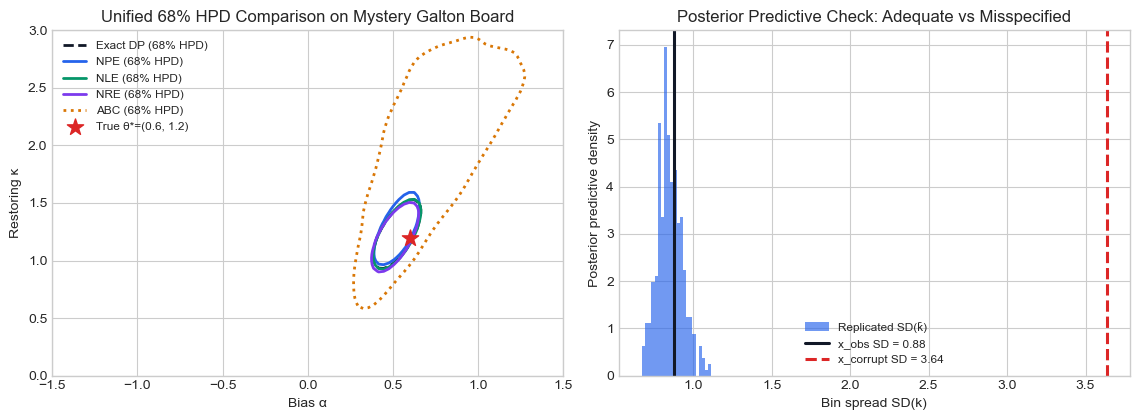

In [9]:
def exact_bin_probs(alpha: np.ndarray, kappa: np.ndarray, n_rows: int = N_ROWS) -> np.ndarray:
    a, k = np.broadcast_arrays(np.asarray(alpha, dtype=float), np.asarray(kappa, dtype=float))
    pi_t = np.zeros(a.shape + (1,), dtype=float)
    pi_t[..., 0] = 1.0
    sqrt_r = np.sqrt(float(n_rows))
    for t in range(n_rows):
        s_t = 2.0 * np.arange(t + 1, dtype=float) - float(t)
        p_r = scipy.special.expit(a[..., None] - k[..., None] * (s_t / sqrt_r))
        nxt = np.zeros(a.shape + (t + 2,), dtype=float)
        nxt[..., :-1] += pi_t * (1.0 - p_r)
        nxt[..., 1:] += pi_t * p_r
        pi_t = nxt
    return pi_t / np.sum(pi_t, axis=-1, keepdims=True)


def hpd_threshold(post: np.ndarray, cred: float = 0.68) -> float:
    flat = np.sort(post.ravel())[::-1]
    csum = np.cumsum(flat) * da * dk
    idx = min(np.searchsorted(csum, cred), flat.size - 1)
    return float(flat[idx])


# Exact DP posterior on the same 101x101 grid
dp_probs = exact_bin_probs(AA, KK)
log_like_dp = np.sum(scipy.special.xlogy(x_obs[None, None, :], dp_probs), axis=-1)
post_exact = np.exp(log_like_dp - log_like_dp.max())
post_exact /= np.sum(post_exact) * da * dk

with torch.no_grad():
    lp_npe = npe_model.log_prob(grid_t, x_obs_t).numpy().reshape(AA.shape)
post_npe = np.exp(lp_npe - lp_npe.max())
post_npe /= np.sum(post_npe) * da * dk

# KDE of Wasserstein ABC accepted draws on the grid
acc_w = thetas_abc[d_wass < 0.34]
kde_abc = scipy.stats.gaussian_kde(acc_w.T)(np.vstack([AA.ravel(), KK.ravel()])).reshape(AA.shape)
post_abc = kde_abc / (np.sum(kde_abc) * da * dk)

for name, p_approx in [("ABC (W1)", post_abc), ("NPE", post_npe), ("NLE", post_nle_flat), ("NRE", post_nre)]:
    tv = 0.5 * np.sum(np.abs(p_approx - post_exact)) * da * dk
    print(f"TV({name:8s}, Exact DP) = {tv:.3f}")

# Overlay 68% HPD contours + Posterior Predictive Check
x_corrupt = np.array([2, 6, 14, 15, 6, 2, 1, 2, 8, 18, 16, 8, 2], dtype=int)
ppc_thetas = npe_model.sample(x_obs, n_samples=400, seed=77)
ppc_reps = simulate_galton_board(ppc_thetas[:, 0], ppc_thetas[:, 1], rng=np.random.default_rng(77))
_, ppc_vars = hist_moments(ppc_reps)
ppc_sds = np.sqrt(ppc_vars)
sd_obs = float(np.sqrt(hist_moments(x_obs[None, :])[1][0]))
sd_corrupt = float(np.sqrt(hist_moments(x_corrupt[None, :])[1][0]))
print(f"PPC P(SD(x_rep) >= SD(x_obs))     = {np.mean(ppc_sds >= sd_obs):.3f} (compatible)")
print(f"PPC P(SD(x_rep) >= SD(x_corrupt)) = {np.mean(ppc_sds >= sd_corrupt):.3f} (misspecified!)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.3))
for label, post_m, col, ls in [
    ("Exact DP", post_exact, "#111827", "--"),
    ("NPE", post_npe, "#2563eb", "-"),
    ("NLE", post_nle_flat, "#059669", "-"),
    ("NRE", post_nre, "#7c3aed", "-"),
    ("ABC", post_abc, "#d97706", ":"),
]:
    lv = hpd_threshold(post_m, 0.68)
    ax1.contour(AA, KK, post_m, levels=[lv], colors=[col], linestyles=[ls], linewidths=2.0)
    ax1.plot([], [], color=col, linestyle=ls, linewidth=2.0, label=f"{label} (68% HPD)")
ax1.scatter([0.60], [1.20], marker="*", s=150, color="#dc2626", zorder=6, label="True θ*=(0.6, 1.2)")
ax1.set_xlim(ALPHA_MIN, ALPHA_MAX)
ax1.set_ylim(KAPPA_MIN, KAPPA_MAX)
ax1.set_xlabel("Bias α")
ax1.set_ylabel("Restoring κ")
ax1.set_title("Unified 68% HPD Comparison on Mystery Galton Board")
ax1.legend(loc="upper left", fontsize=8.5)

ax2.hist(ppc_sds, bins=22, density=True, alpha=0.65, color="#2563eb", label="Replicated SD(k̃)")
ax2.axvline(sd_obs, color="#111827", lw=2.2, label=f"x_obs SD = {sd_obs:.2f}")
ax2.axvline(sd_corrupt, color="#dc2626", lw=2.2, ls="--", label=f"x_corrupt SD = {sd_corrupt:.2f}")
ax2.set_xlabel("Bin spread SD(k)")
ax2.set_ylabel("Posterior predictive density")
ax2.set_title("Posterior Predictive Check: Adequate vs Misspecified")
ax2.legend(fontsize=8.5)
plt.tight_layout()
plt.show()

In [11]:
iw.demo("w12_unified_compare")

<InteractiveDemo w12_unified_compare: W12: Unified Galton-Board Comparison (ABC vs NPE vs NLE vs NRE vs Exact)>